# 03 · Time, drift, signal, redundancy, proxy entity and leakage

**FinGuard AI, Phase 1.** Reads the joined tables saved by notebook 01.

Questions answered here:
1. Is the fraud problem stable over time? What does the later (unlabelled) period look like?
2. Which features drift between training and the later period?
3. How much signal does each feature carry on its own, and how much is redundant?
4. What can a **proxy entity** tell us, and why it is **not** customer profiling?
5. Which leakage risks must Phase 2 guard against?

**Figures:** fig02, fig03, fig04, fig13, fig14, fig15, fig16.
**Tables:** train_vs_later_drift, univariate_signal, redundancy, d_column_trend,
category_novelty, leakage_risks, proxy_entity_summary.

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from finguard import config
from finguard.data.ingest import load_table
from finguard.eda import figures as F, missingness as M, signal as SG, drift as DR, style as S
from finguard.features import normalize as N, proxy_entity as P

pd.set_option("display.max_columns", 30, "display.width", 160)
train, test = load_table("train"), load_table("test")
y = train[config.TARGET]
FEATS = M.feature_columns(train)
STATS = {}
print(train.shape, test.shape, len(FEATS), "feature columns")

(590540, 438) (506691, 437) 432 feature columns


## 1. Time
TransactionDT is relative: day 0 is the first training transaction, and hours and weekdays
are relative to an undisclosed clock.

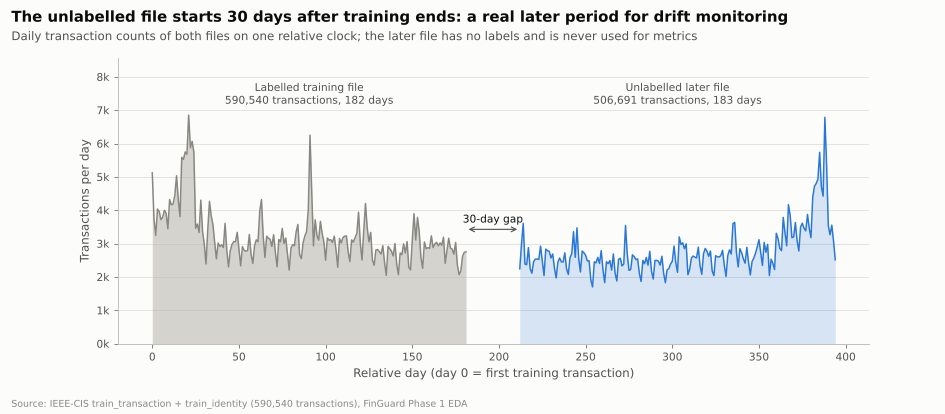

In [2]:
fig = F.fig03_daily_volume(train, test)

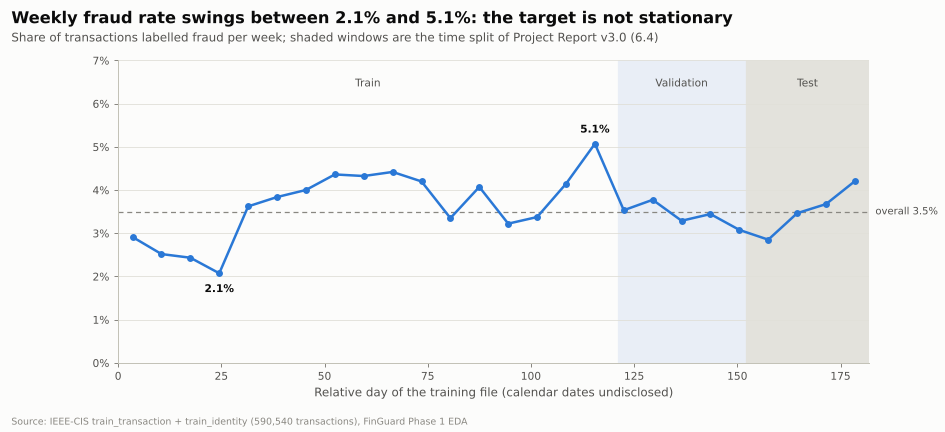

,size,mean
30-day block,,
0,134339,0.0253
1,89399,0.0400
2,92189,0.0404
3,98615,0.0395
4,83571,0.0341
5,92427,0.0348


In [3]:
fig = F.fig02_weekly_fraud_rate(train)
w = train.groupby(train.day // 7)[config.TARGET].mean()
STATS["weekly_rate_min"], STATS["weekly_rate_max"] = float(w.min()), float(w.max())
blocks30 = train.groupby((train.day // 30).clip(upper=5))[config.TARGET].agg(["size", "mean"]).rename_axis("30-day block")
STATS["rate_by_30d_block"] = blocks30["mean"].round(4).to_dict()
blocks30.round(4)

relative weekday fraud rates range 3.15% - 3.72% (weak)


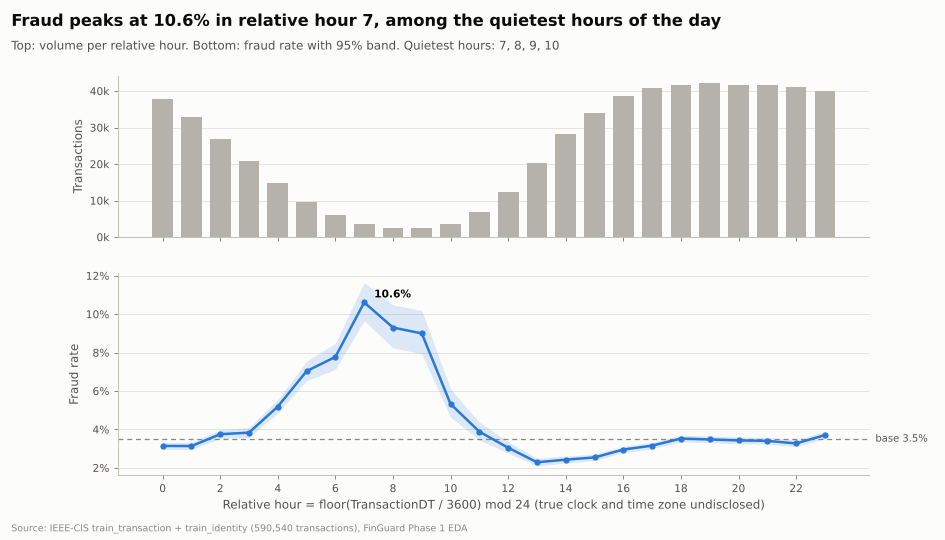

In [4]:
fig = F.fig04_hourly_profile(train)
h = train.groupby("rel_hour")[config.TARGET].agg(["size", "mean"])
STATS["hour_peak"] = {"hour": int(h["mean"].idxmax()), "rate": float(h["mean"].max())}
wd = train.groupby("rel_weekday")[config.TARGET].agg(["size", "mean"]).round(4)
print("relative weekday fraud rates range", f"{wd['mean'].min():.2%} - {wd['mean'].max():.2%} (weak)")

## 2. Drift between training and the later period
Single-feature adversarial AUC: how well one feature alone tells a training row from a
later row. 0.5 means no drift. This is measurable without labels, so it is also the
production monitoring signal.

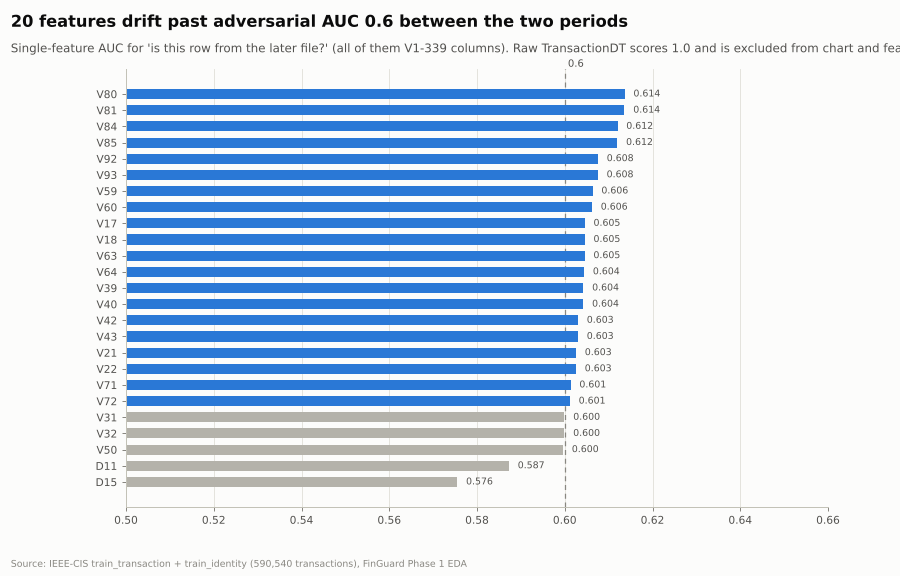

,max,median
group,,
TransactionDT,1.000,1.000
V1-339,0.614,0.516
D1-15,0.587,0.538
M1-9,0.564,0.554
C1-14,0.551,0.511
id_01-38,0.519,0.511
DeviceType/Info,0.519,0.517
email,0.518,0.512
ProductCD,0.516,0.516


In [5]:
drift = DR.adversarial_auc_per_feature(train, test, FEATS)
drift.to_csv(config.TABLE_DIR / "train_vs_later_drift.csv", index=False)
STATS["drift_over_0.6"] = int((drift[drift.column != config.TIME].adversarial_auc > 0.6).sum())
fig = F.fig14_adversarial_drift(drift)
drift.groupby("group").adversarial_auc.agg(["max", "median"]).round(3).sort_values("max", ascending=False)

### Category novelty: why raw strings must be normalised
Share of later-period values never seen in training, before and after normalisation.

In [6]:
nov = []
for col, fn in [("id_31", N.browser_family), ("id_30", N.os_family), ("DeviceInfo", N.device_brand),
                ("P_emaildomain", N.email_group), ("R_emaildomain", N.email_group)]:
    nov.append({"column": col, "raw: new in later period": DR.new_category_share(train[col], test[col]),
                "normalised: new in later period": DR.new_category_share(fn(train[col]), fn(test[col]))})
for col in ["card1", "addr1"]:
    nov.append({"column": col, "raw: new in later period": DR.new_category_share(train[col], test[col]),
                "normalised: new in later period": np.nan})
nov = pd.DataFrame(nov).set_index("column")
nov.to_csv(config.TABLE_DIR / "category_novelty.csv")
STATS["id_31_new_raw"] = float(nov.loc["id_31"].iloc[0])
nov.round(4)

,raw: new in later period,normalised: new in later period
column,,
id_31,0.6057,0.0
id_30,0.2417,0.0
DeviceInfo,0.1379,0.0
P_emaildomain,0.0000,0.0
R_emaildomain,0.0000,0.0
card1,0.0185,NaN
addr1,0.0004,NaN


### D-columns trend with time
The host describes D-columns only as "timedelta". Several rise with the calendar, which
makes their raw values non-stationary. Normalising as `day - D` removes the trend.

In [7]:
dcols = [c for c in FEATS if c.startswith("D") and c[1:].isdigit()]
trend = pd.Series({c: train[[c, "day"]].dropna().corr("spearman").iloc[0, 1] for c in dcols}, name="spearman_with_day")
trend.to_csv(config.TABLE_DIR / "d_column_trend.csv")
STATS["d_trend"] = trend.round(3).to_dict()
d1n = np.floor(train[config.TIME] / config.SECONDS_PER_DAY) - train.D1
pd.DataFrame({"D1 median": train.groupby(train.day // 30).D1.median(),
              "day - D1 median": d1n.groupby(train.day // 30).median()}).rename_axis("30-day block")

,D1 median,day - D1 median
30-day block,,
0,0.0,9.0
1,7.0,32.0
2,6.0,62.0
3,3.0,92.0
4,16.0,117.0
5,14.0,150.0
6,14.0,167.0


## 3. Single-feature signal
Honest strength per feature: categorical columns are target-encoded on the first 60% of
time and scored on the last 40%; numeric columns are ranked with NaN lowest.

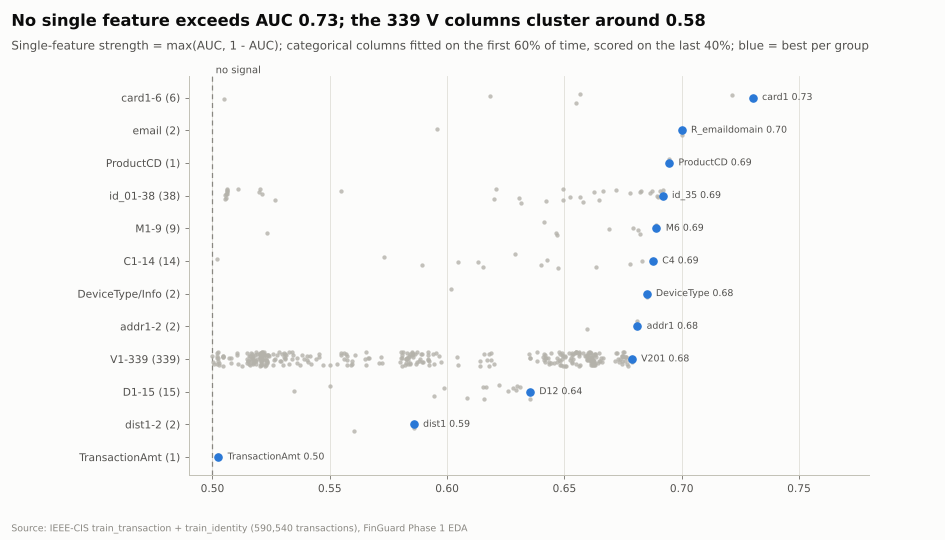

,column,group,kind,auc,auc_first_half,auc_second_half,n_unique,strength,half_shift
0,card1,card1-6,"categorical (fit early, score late)",0.7303,NaN,NaN,13553,0.7303,NaN
1,card2,card1-6,"categorical (fit early, score late)",0.7216,NaN,NaN,500,0.7216,NaN
2,R_emaildomain,email,"categorical (fit early, score late)",0.7000,NaN,NaN,60,0.7000,NaN
3,ProductCD,ProductCD,"categorical (fit early, score late)",0.6946,NaN,NaN,5,0.6946,NaN
4,id_35,id_01-38,"categorical (fit early, score late)",0.6918,NaN,NaN,2,0.6918,NaN
5,id_15,id_01-38,"categorical (fit early, score late)",0.6906,NaN,NaN,3,0.6906,NaN
6,id_29,id_01-38,"categorical (fit early, score late)",0.6897,NaN,NaN,2,0.6897,NaN
7,id_28,id_01-38,"categorical (fit early, score late)",0.6895,NaN,NaN,2,0.6895,NaN
8,M6,M1-9,"categorical (fit early, score late)",0.6892,NaN,NaN,2,0.6892,NaN
9,C4,C1-14,"numeric (rank, NaN lowest)",0.6877,0.6838,0.6932,1260,0.6877,0.0094


In [8]:
sig = SG.univariate_strength(train, [c for c in FEATS if c != config.TIME])
sig.to_csv(config.TABLE_DIR / "univariate_signal.csv", index=False)
STATS["max_single_strength"] = float(sig.strength.max())
STATS["n_weak_lt_0.52"] = int((sig.strength < 0.52).sum())
fig = F.fig13_signal_by_group(sig)
sig.head(15).round(4)

In [9]:
print("Least stable numeric features (AUC first half vs second half):")
sig.dropna(subset=["half_shift"]).sort_values("half_shift", ascending=False).head(10)[
    ["column", "group", "auc_first_half", "auc_second_half", "half_shift"]].round(4)

Least stable numeric features (AUC first half vs second half):


,column,group,auc_first_half,auc_second_half,half_shift
154,V10,V1-339,0.4041,0.3052,0.0990
155,V11,V1-339,0.4041,0.3053,0.0988
170,D11,D1-15,0.4113,0.3202,0.0911
185,V4,V1-339,0.4178,0.3425,0.0753
179,V1,V1-339,0.4155,0.3407,0.0748
181,V6,V1-339,0.4163,0.3419,0.0745
182,V8,V1-339,0.4160,0.3429,0.0732
186,V7,V1-339,0.4178,0.3446,0.0731
184,V2,V1-339,0.4167,0.3436,0.0731
193,V5,V1-339,0.4203,0.3476,0.0727


## 4. Redundancy
Inside each missing-value block, a column is redundant if it correlates at |r| >= 0.95
with an earlier kept column. C1-C14 have no missing values and are checked as one group.

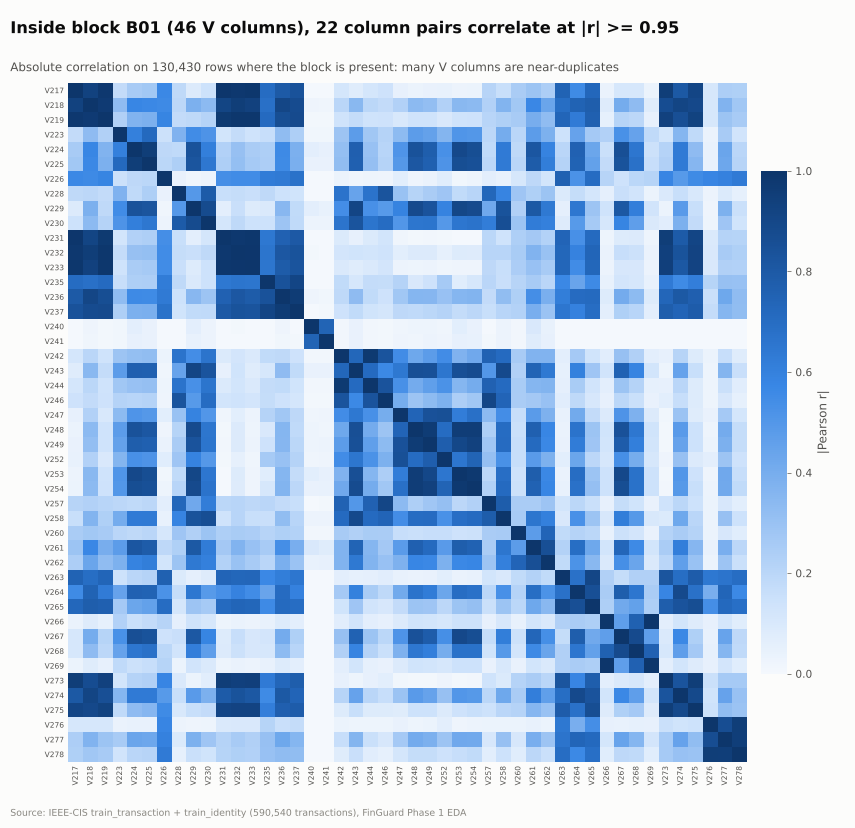

,checked,redundant
group,,
C1-14,14,8
D1-15,4,0
V1-339,339,83
addr1-2,2,0
id_01-38,8,0


In [10]:
blocks = M.nan_blocks(train)
c_block = pd.DataFrame([{"block": "C", "columns": [f"C{i}" for i in range(1, 15)]}])
red = pd.concat([SG.redundant_within_blocks(train, blocks), SG.redundant_within_blocks(train, c_block)], ignore_index=True)
red.to_csv(config.TABLE_DIR / "redundancy.csv", index=False)
from finguard.data.schema import feature_group
red["group"] = red.column.map(feature_group)
summary = red.groupby("group").redundant.agg(checked="size", redundant="sum")
STATS["redundant"] = summary.to_dict("index")
fig = F.fig16_vblock_correlation(train, blocks)
summary

## 5. Proxy entity: what it is and what it is not

> **IEEE-CIS has no customer, account or cardholder ID.** The proxy entity groups
> transactions sharing card1, addr1 and the same first-seen day (day - D1). It is a
> heuristic from the 2019 competition's top solutions. Analyses below are
> **proxy-entity analysis**, never customer profiling.

| Proxy-entity analysis can say | It cannot say |
| --- | --- |
| "This card/address/first-seen group made 6 transactions in 24 h" | "This customer made 6 transactions" |
| "The amount is 8x the group's earlier average" | "The customer's normal spending is X" |
| "This group's labels are uniform" | "This person is a fraudster" |
| Velocity and consistency features for the model | Customer risk scores, customer segments, KYC conclusions |

In [11]:
entity = P.build_proxy_entity(train)
cov = P.coverage(entity)
purity = P.label_purity(entity, y)
with_fraud = purity[purity.frauds > 0]
cov.update({"entities_2plus_with_any_fraud": int(len(with_fraud)),
            "share_entirely_fraud": float((with_fraud.fraud_share == 1).mean()),
            "share_of_multi_entities_mixed": float(((purity.fraud_share > 0) & (purity.fraud_share < 1)).mean())})
c1 = P.label_purity(train.card1.astype("Int64").astype("string"), y)
cov["card1_groups_with_fraud_entirely_fraud"] = float((c1[c1.frauds > 0].fraud_share == 1).mean())
pd.Series(cov).to_frame("value")

,value
rows_with_entity,0.886893
n_entities,199070.000000
n_single_transaction_entities,115513.000000
n_multi_transaction_entities,83557.000000
share_of_all_rows_in_multi_entities,0.691288
share_of_entity_rows_in_multi_entities,0.779448
median_size_of_multi_entities,3.000000
entities_2plus_with_any_fraud,2716.000000
share_entirely_fraud,0.546392
share_of_multi_entities_mixed,0.014744


### Why random splits leak
Labels are almost uniform inside an entity (the host's labelling propagates fraud to
later linked transactions). A random split puts the same entity on both sides, so a model
can recognise entities instead of learning fraud.

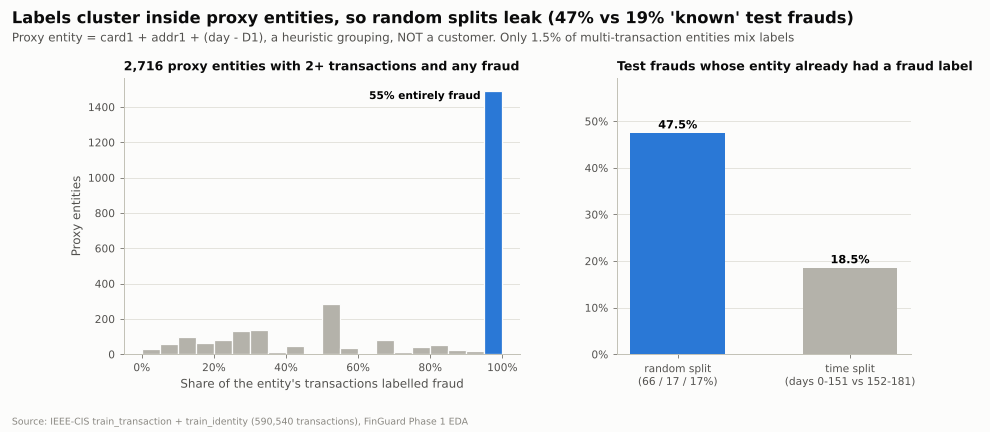

,random split,time split
test_rows_entity_seen_in_train,0.6703,0.4306
test_frauds_entity_had_fraud_in_train,0.4747,0.1854
fraud_rate_if_entity_had_fraud,0.6279,0.5949
fraud_rate_otherwise,0.0192,0.0289


In [12]:
rng = np.random.default_rng(config.RANDOM_SEED)
r = rng.random(len(train))
rand_tr, rand_te = r < 0.83, r >= 0.83
time_tr, time_te = (train.day <= config.SPLIT_DAYS["valid"][1]).to_numpy(), (train.day >= config.SPLIT_DAYS["test"][0]).to_numpy()
ov_random = P.split_overlap(entity, y, rand_tr, rand_te)
ov_time = P.split_overlap(entity, y, time_tr, time_te)
fig = F.fig15_entity_label_purity(purity, ov_random, ov_time)
cov.update({"overlap_random": ov_random, "overlap_time": ov_time})
(config.TABLE_DIR / "proxy_entity_summary.json").write_text(json.dumps(cov, indent=2, default=float))
pd.DataFrame({"random split": ov_random, "time split": ov_time}).round(4)

## 6. Leakage risk register
Every risk below is backed by a number computed in notebooks 01-03 and maps to a rule
Phase 2 must enforce (and test).

In [13]:
rho = train[[config.KEY, config.TIME]].corr("spearman").iloc[0, 1]
risks = pd.DataFrame([
    ["Random train/test split", f"{ov_random['test_frauds_entity_had_fraud_in_train']:.1%} of random-split test frauds belong to an entity already labelled fraud (time split: {ov_time['test_frauds_entity_had_fraud_in_train']:.1%})",
     "critical", "Time-ordered split only; report new vs known entities separately"],
    ["Entity label propagation", f"{cov['share_entirely_fraud']:.1%} of multi-transaction entities with fraud are entirely fraud; only {cov['share_of_multi_entities_mixed']:.1%} mix labels",
     "critical", "No target encoding of entities or card codes; label-delay gap in a sensitivity run"],
    ["TransactionID as a feature", f"Spearman with time = {rho:.4f}", "high", "Exclude"],
    ["Raw TransactionDT as a feature", "Adversarial AUC 1.0: later values never occur in training", "high", "Exclude; derive relative hour and weekday only"],
    ["Raw D-columns", f"Spearman with day up to {trend.abs().max():.2f}", "medium", "Normalise as day - D"],
    ["Statistics fitted on all data", "Frequencies, bins, medians, encoders computed over train + later rows", "high", "Fit every statistic on the training period only"],
    ["Whole-period entity aggregates", "Entity means over all rows use future transactions", "high", "Compute entity features from earlier rows only (time-ordered replay)"],
    ["Imputing informative missingness", "Present vs missing blocks differ up to several-fold in fraud rate (fig06)", "medium", "NaN for trees; block indicators for linear models"],
    ["Raw version and device strings", f"{STATS['id_31_new_raw']:.1%} of later browser strings unseen in training", "medium", "Normalise to families; monitor novelty"],
    ["Calibration and thresholds on the test month", "Would make the test month part of training", "high", "Fit calibrator and bands on the validation month; freeze before testing"],
], columns=["risk", "evidence", "severity", "rule for Phase 2"])
risks.to_csv(config.TABLE_DIR / "leakage_risks.csv", index=False)
risks

,risk,evidence,severity,rule for Phase 2
0,Random train/test split,47.5% of random-split test frauds belong to an...,critical,Time-ordered split only; report new vs known e...
1,Entity label propagation,54.6% of multi-transaction entities with fraud...,critical,No target encoding of entities or card codes; ...
2,TransactionID as a feature,Spearman with time = 1.0000,high,Exclude
3,Raw TransactionDT as a feature,Adversarial AUC 1.0: later values never occur ...,high,Exclude; derive relative hour and weekday only
4,Raw D-columns,Spearman with day up to 0.12,medium,Normalise as day - D
5,Statistics fitted on all data,"Frequencies, bins, medians, encoders computed ...",high,Fit every statistic on the training period only
6,Whole-period entity aggregates,Entity means over all rows use future transact...,high,Compute entity features from earlier rows only...
7,Imputing informative missingness,Present vs missing blocks differ up to several...,medium,NaN for trees; block indicators for linear models
8,Raw version and device strings,60.6% of later browser strings unseen in training,medium,Normalise to families; monitor novelty
9,Calibration and thresholds on the test month,Would make the test month part of training,high,Fit calibrator and bands on the validation mon...


In [14]:
(config.TABLE_DIR / "phase1_stats_03.json").write_text(json.dumps(STATS, indent=2, default=float))
print(json.dumps({k: STATS[k] for k in ["weekly_rate_min", "weekly_rate_max", "hour_peak", "drift_over_0.6",
                                        "max_single_strength", "n_weak_lt_0.52", "redundant"]}, indent=1, default=float))

{
 "weekly_rate_min": 0.02074141981321263,
 "weekly_rate_max": 0.05071638675396148,
 "hour_peak": {
  "hour": 7,
  "rate": 0.10610151187904968
 },
 "drift_over_0.6": 20,
 "max_single_strength": 0.7302572164623795,
 "n_weak_lt_0.52": 65,
 "redundant": {
  "C1-14": {
   "checked": 14,
   "redundant": 8
  },
  "D1-15": {
   "checked": 4,
   "redundant": 0
  },
  "V1-339": {
   "checked": 339,
   "redundant": 83
  },
  "addr1-2": {
   "checked": 2,
   "redundant": 0
  },
  "id_01-38": {
   "checked": 8,
   "redundant": 0
  }
 }
}


## Findings
* **The target drifts**: weekly fraud rate ranges roughly from 2% to 5%; the first month runs
  lower than the next three. Time-ordered evaluation is mandatory.
* **A real later period exists**: the unlabelled file starts 30 days after training and runs
  183 days. Features drift (adversarial AUC above 0.6 for a group of V columns), browser
  strings are mostly new, and normalising to families removes most of that novelty.
* **Signal is spread thin**: no single feature exceeds AUC 0.73; many V columns are weak and
  a large share are near-duplicates inside their blocks.
* **Proxy entity**: covers about 89% of rows; labels are almost uniform inside entities, which
  is consistent with the host's label propagation and makes random splits leak heavily.
* The leakage register above lists the ten rules Phase 2 must implement and test.